# Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

wti_file = pd.read_csv('wti-daily.csv')
brent_file = pd.read_csv('brent-daily.csv')

print('WTI FILE: \n',  wti_file.head())
print('BRENT FILE: \n', brent_file.head())

WTI FILE: 
          Date  Price
0  1986-01-02  25.56
1  1986-01-03  26.00
2  1986-01-06  26.53
3  1986-01-07  25.85
4  1986-01-08  25.87
BRENT FILE: 
          Date  Price
0  1987-05-20  18.63
1  1987-05-21  18.45
2  1987-05-22  18.55
3  1987-05-25  18.60
4  1987-05-26  18.63


In [2]:
wti_file['Date'] = pd.to_datetime(wti_file['Date'])
brent_file['Date'] = pd.to_datetime(brent_file['Date'])

#skip year 1986 as data for that year is missing in one of the files.
wti_file = wti_file[
    (wti_file['Date'].dt.year >= 1987) & #filter to year
    (wti_file['Date'].dt.month >= 5) & #filter to month
    (wti_file['Date'].dt.day >= 20) #filter to day
]

print('WTI FILE: \n',  wti_file)
print('BRENT FILE: \n', brent_file)


WTI FILE: 
             Date  Price
346   1987-05-20  19.75
347   1987-05-21  19.95
348   1987-05-22  19.68
349   1987-05-26  19.35
350   1987-05-27  19.38
...          ...    ...
10020 2025-10-21  58.66
10021 2025-10-22  59.30
10022 2025-10-23  62.44
10023 2025-10-24  62.27
10024 2025-10-27  62.13

[2442 rows x 2 columns]
BRENT FILE: 
            Date  Price
0    1987-05-20  18.63
1    1987-05-21  18.45
2    1987-05-22  18.55
3    1987-05-25  18.60
4    1987-05-26  18.63
...         ...    ...
9749 2025-10-21  61.00
9750 2025-10-22  62.28
9751 2025-10-23  66.32
9752 2025-10-24  65.80
9753 2025-10-27  65.52

[9754 rows x 2 columns]


# Question 1 and 2


In [3]:
wti_year_avg = wti_file.groupby(
    wti_file['Date'].dt.year
)['Price'].mean()

brent_year_avg = brent_file.groupby(
    brent_file['Date'].dt.year
)['Price'].mean()

print('wti avg', wti_year_avg.head())
print('brent avg', brent_year_avg.head())


wti avg Date
1987    19.510794
1988    15.558030
1989    19.784242
1990    26.457077
1991    21.406250
Name: Price, dtype: float64
brent avg Date
1987    18.525813
1988    14.905412
1989    18.228228
1990    23.761445
1991    20.041128
Name: Price, dtype: float64


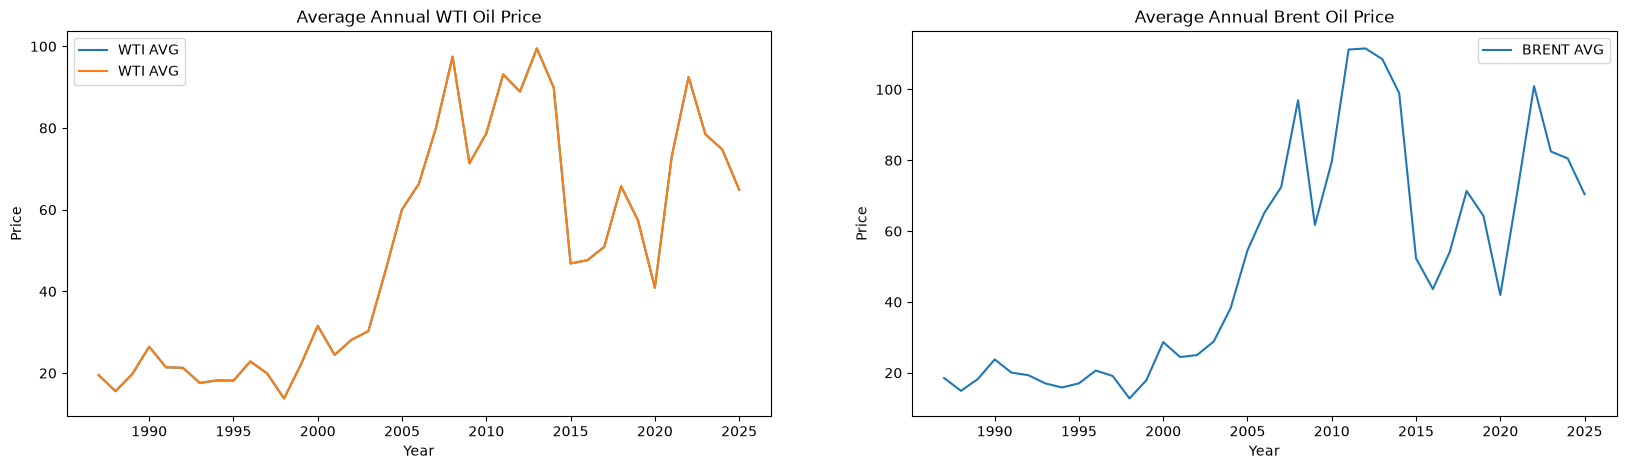

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(20,5))

ax[0].plot(wti_year_avg.index, wti_year_avg.values, label='WTI AVG')

ax[0].plot(wti_year_avg.index, wti_year_avg.values, label='WTI AVG')
ax[0].set_xlabel('Year')
ax[0].set_ylabel('Price')
ax[0].set_title('Average Annual WTI Oil Price')
ax[0].legend()

ax[1].plot(brent_year_avg.index, brent_year_avg.values, label='BRENT AVG')
ax[1].set_xlabel('Year')
ax[1].set_ylabel('Price')
ax[1].set_title('Average Annual Brent Oil Price')
ax[1].legend()

# questoin 3

In [5]:
wti_year_avg = wti_year_avg.loc[1992:2002]
brent_year_avg = brent_year_avg.loc[1992:2002]

print(wti_year_avg)
print(brent_year_avg)

Date
1992    21.288730
1993    17.590159
1994    18.200952
1995    18.145714
1996    22.861270
1997    19.889836
1998    13.790000
1999    22.089841
2000    31.561406
2001    24.450806
2002    28.150645
Name: Price, dtype: float64
Date
1992    19.319728
1993    17.013413
1994    15.856389
1995    17.015850
1996    20.639803
1997    19.108508
1998    12.758103
1999    17.901566
2000    28.660672
2001    24.455720
2002    24.993255
Name: Price, dtype: float64


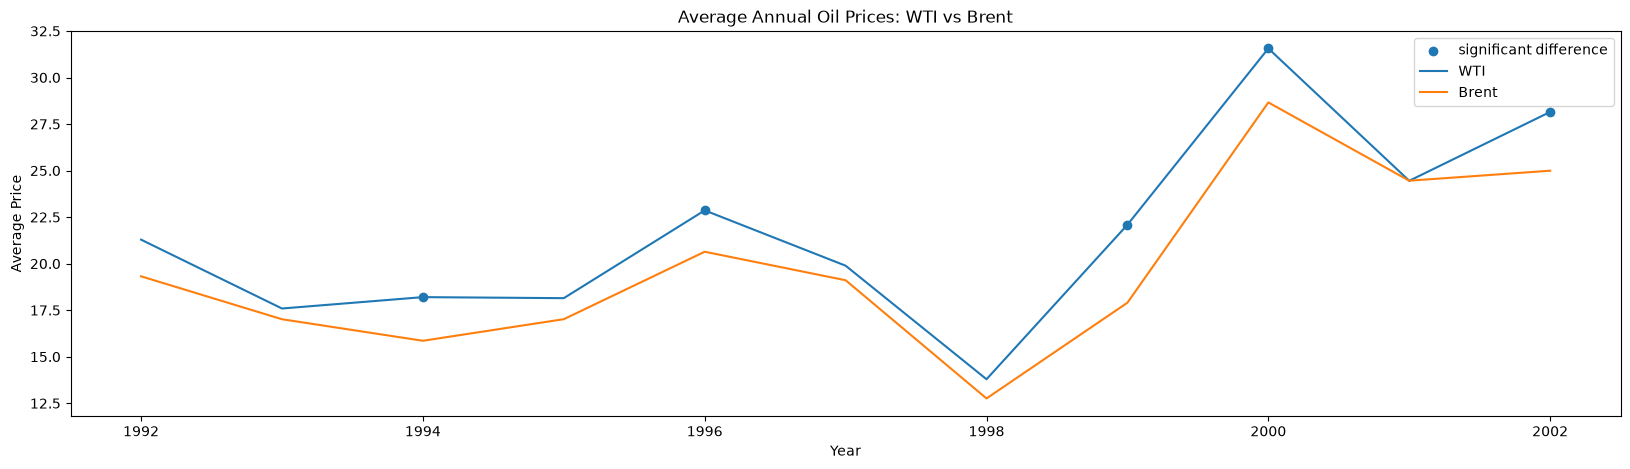

In [6]:
fig1, ax1 = plt.subplots(figsize=(20,5))



difference = (wti_year_avg - brent_year_avg).abs()
significant_years = difference[difference > 2]

ax1.scatter(
    significant_years.index,
    wti_year_avg.loc[significant_years.index],
    marker='o',
    label='significant difference'
)

# ax1.scatter(
#     significant_years.index,
#     brent_year_avg.loc[significant_years.index],
#     marker='o',
#     label='significant difference'
# )

ax1.plot(wti_year_avg.index, wti_year_avg.values, label='WTI')
ax1.plot(brent_year_avg.index, brent_year_avg.values, label='Brent')

ax1.set_xlabel('Year')
ax1.set_ylabel('Average Price')
ax1.set_title('Average Annual Oil Prices: WTI vs Brent')
ax1.legend()

# qeustion 4

In [7]:
sales_file = pd.read_excel('sales.xlsx')
print(sales_file.head())


    Invoice ID Branch       City Customer type  Gender  Product Code  \
0  123-19-1176      A     Yangon        Member    Male             1   
1  699-14-3026      C  Naypyitaw        Normal    Male             1   
2  355-53-5943      A     Yangon        Member  Female             1   
3  315-22-5665      C  Naypyitaw        Normal  Female             1   
4  692-92-5582      B   Mandalay        Member  Female             1   

   Unit price  Quantity   Tax 5%     Total       Date      Payment    COGS  \
0       58.22         8  23.2880  489.0480 2019-01-27      Ewallet  465.76   
1       85.39         7  29.8865  627.6165 2019-03-25      Ewallet  597.73   
2       68.84         6  20.6520  433.6920 2019-02-25      Ewallet  413.04   
3       73.56        10  36.7800  772.3800 2019-02-24      Ewallet  735.60   
4       54.84         3   8.2260  172.7460 2019-02-20  Credit card  164.52   

   gross margin percentage  gross income  Rating  
0                 4.761905       23.2880     8.

In [12]:
sales = sales_file.groupby('City')['Total'].sum()
sales = sales.sort_values(ascending=False)

print(sales.head())

City
Naypyitaw    110568.7065
Yangon       106200.3705
Mandalay     106197.6720
Name: Total, dtype: float64


Text(0.5, 1.0, 'Sales distributions per city - TOTAL')

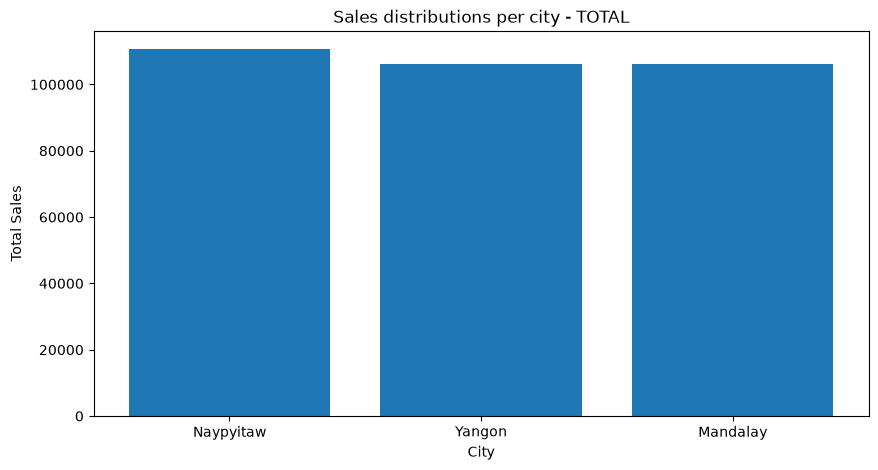

In [13]:
fig2, ax2 = plt.subplots(figsize=(10, 5))

ax2.bar(sales.index, sales.values)

ax2.set_xlabel('City')
ax2.set_ylabel('Total Sales')
ax2.set_title('Sales distributions per city - TOTAL')


# question 5

In [14]:
payment_method = sales_file.groupby('Payment')['Total'].sum()
payment_method = payment_method.sort_values(ascending=False)

print(payment_method)

Payment
Cash           112206.570
Ewallet        109993.107
Credit card    100767.072
Name: Total, dtype: float64


Text(0.5, 1.0, 'Total Sales Distribution by Payment Method')

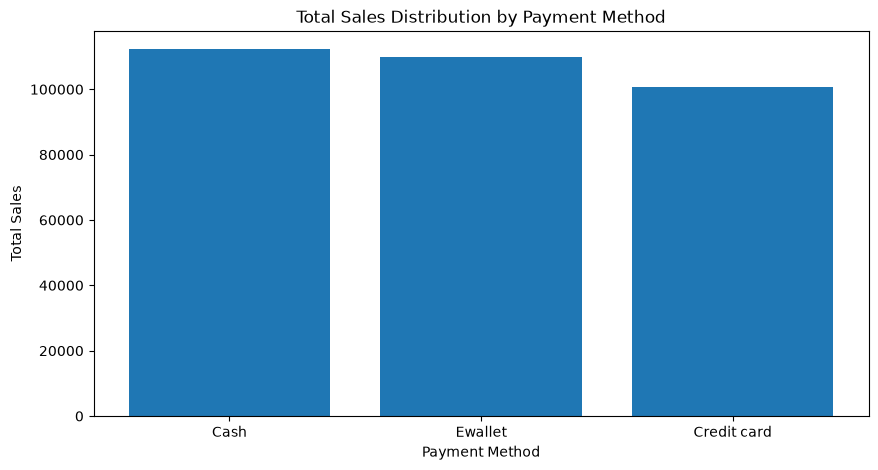

In [15]:
fig3, ax3 = plt.subplots(figsize=(10, 5))

ax3.bar(payment_method.index, payment_method.values)

ax3.set_xlabel('Payment Method')
ax3.set_ylabel('Total Sales')
ax3.set_title('Total Sales Distribution by Payment Method')

Cash seems to be the method that is contributing the most, however by small margins. There is no significant difference that we can make a conclusion on.

# Question 6


In [36]:
image = plt.imread('2.jpg')

image = np.array(image)

print(type(image))
print(image.shape)
print(image.dtype)

<class 'numpy.ndarray'>
(487, 626, 3)
uint8


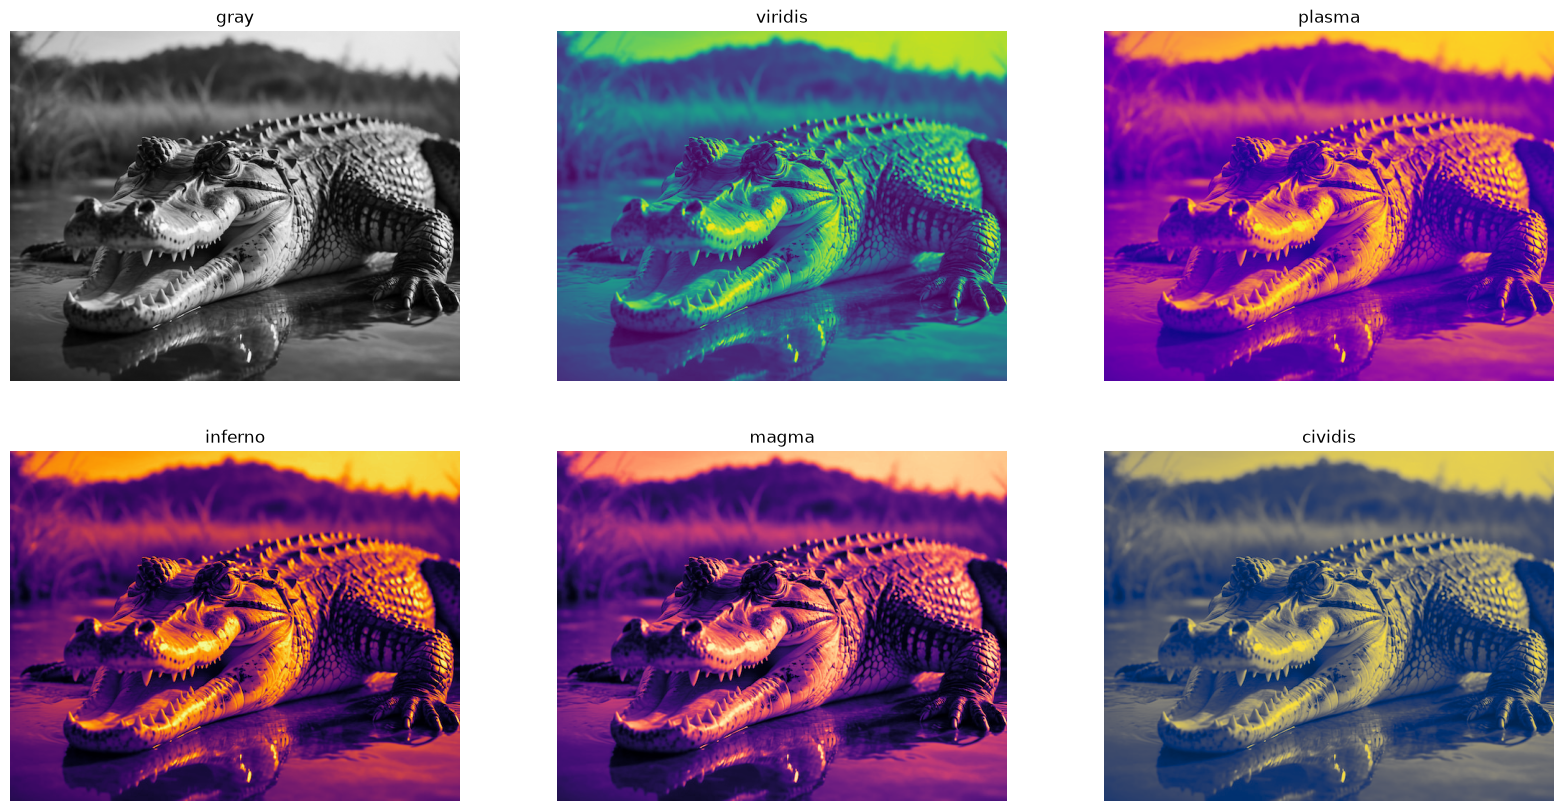

In [39]:
cmaps = ['gray', 'viridis', 'plasma',
         'inferno', 'magma', 'cividis']

gray_image = np.dot(image[..., :3], [0.2989, 0.5870, 0.1140])

fig4, ax4 = plt.subplots(2,3, figsize=(20, 10))

for ax, cmap in zip(ax4.flat, cmaps):
    ax.imshow(gray_image, cmap=cmap)
    ax.set_title(cmap)
    ax.axis('off')

# Question 6

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

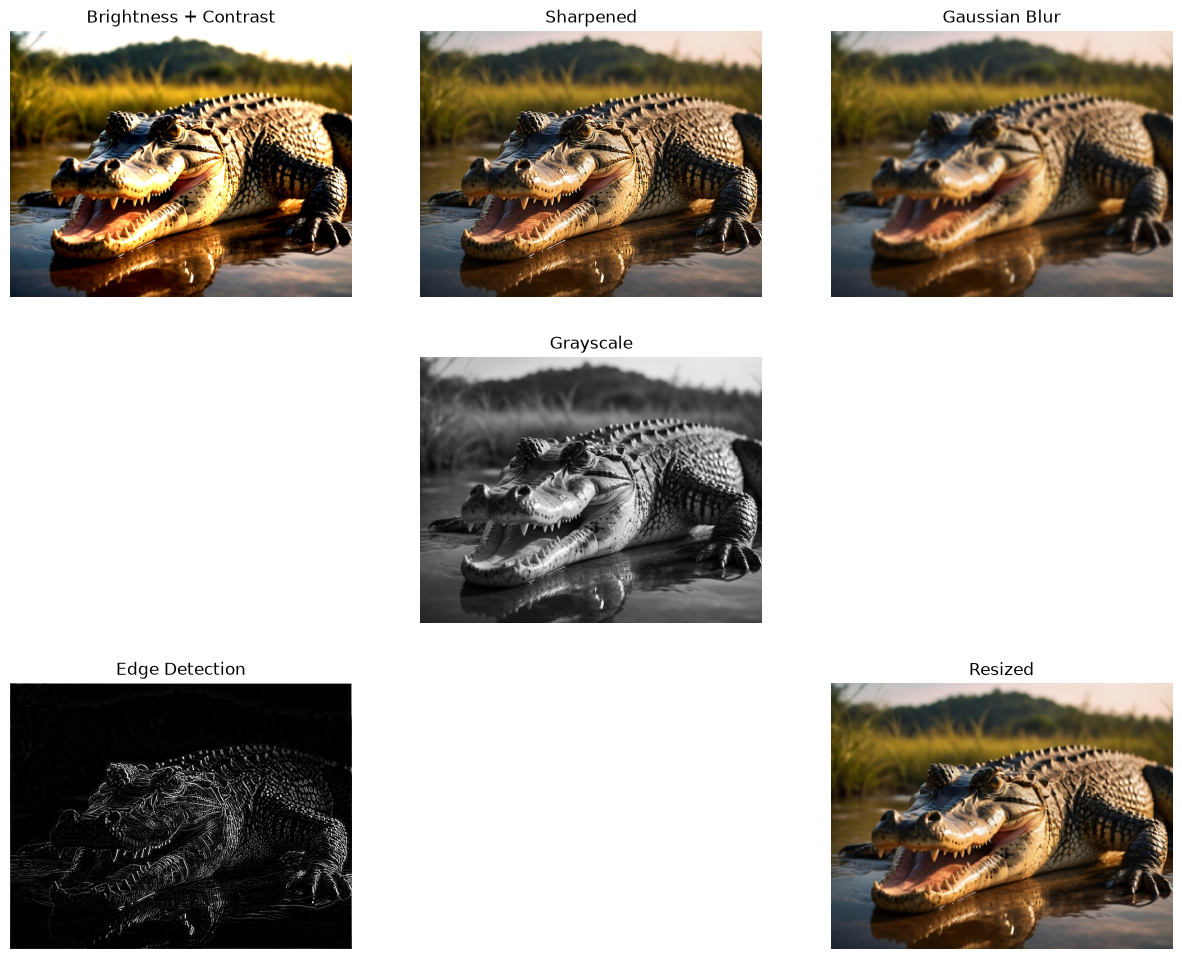

In [ ]:
from PIL import Image, ImageEnhance, ImageFilter, ImageOps

image1 = Image.open('2.jpg')

enhancer_brightness = ImageEnhance.Brightness(image1)
bright_img = enhancer_brightness.enhance(1.2)

enhancer_contrast = ImageEnhance.Contrast(bright_img)
contrast_img = enhancer_contrast.enhance(1.3)

sharpened_img = image1.filter(ImageFilter.SHARPEN)

blurred_img = image1.filter(ImageFilter.GaussianBlur(radius=2))

gray_img = ImageOps.grayscale(image1)

edges_img = gray_img.filter(ImageFilter.FIND_EDGES)

resized_img = image1.resize((image1.width // 2, image1.height // 2))

images = [
    contrast_img,
    sharpened_img,
    blurred_img,
    gray_img,
    edges_img,
    resized_img
]

titles = [
    'Brightness + Contrast',
    'Sharpened',
    'Gaussian Blur',
    'Grayscale',
    'Edge Detection',
    'Resized'
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

positions = [
    (0, 0), (0, 1), (0, 2),
    (1, 1),
    (2, 0), (2, 2)
]

for ax, im, title in zip([axes[r, c] for r, c in positions],images,titles):
    ax.imshow(im, cmap='gray' if im.mode == 'L' else None)
    ax.set_title(title)
    ax.axis('off')

axes[1, 0].axis('off')
axes[1, 2].axis('off')
axes[2, 1].axis('off')